# Treino de classificacao milho (healthy/unhealthy) - YOLO26 no Colab (v2, relatorio completo)

Antes de rodar: no menu **Ambiente de execucao > Alterar tipo de ambiente de execucao**, escolhe **GPU** (T4 e' a gratuita padrao).

Essa versao roda tudo de uma vez so' (Ambiente de execucao > Executar tudo) e no final salva automaticamente TUDO que precisa pro relatorio: estratificacao, loss, accuracy, matriz de confusao, ROC, Precision-Recall e exemplos de predicao. Deixa a aba aberta durante o treino (~2h20min).

In [ ]:
!pip install -q ultralytics scikit-learn
import ultralytics
ultralytics.checks()

Ultralytics 8.4.171 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 43.1/235.7 GB disk)


## Monta o Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Descompacta o dataset

Ajusta `ZIP_PATH` pro nome real do seu arquivo.

In [ ]:
ZIP_PATH = "/content/drive/MyDrive/milho/blick-healthy-unhealthy.folder.zip"
DATASET_DIR = "/content/dataset"

!mkdir -p {DATASET_DIR}
!unzip -q "{ZIP_PATH}" -d {DATASET_DIR}
!echo "Conteudo extraido:" && ls {DATASET_DIR}

Conteudo extraido:
README.roboflow.txt  test  train  valid


## Confere a estrutura de pastas

In [ ]:
import os
for raiz, pastas, arquivos in os.walk(DATASET_DIR):
    nivel = raiz.replace(DATASET_DIR, "").count(os.sep)
    if nivel <= 2:
        print("  " * nivel + os.path.basename(raiz) + f"  ({len(arquivos)} arquivos)")

n_imagens = sum(len(arquivos) for _, _, arquivos in os.walk(DATASET_DIR))
if n_imagens == 0:
    raise SystemExit("Pasta vazia! Confere o ZIP_PATH da celula anterior antes de continuar.")

dataset  (1 arquivos)
  train  (0 arquivos)
    unhealthy  (1744 arquivos)
    healthy  (15905 arquivos)
  valid  (0 arquivos)
    unhealthy  (521 arquivos)
    healthy  (4533 arquivos)
  test  (0 arquivos)
    unhealthy  (250 arquivos)
    healthy  (2267 arquivos)


## Treino

Mesmos hiperparametros da rodada anterior (97.46% accuracy / 82.8% recall em unhealthy, ja aprovada pelo professor), pra manter o resultado comparavel.

In [ ]:
from ultralytics import YOLO

MODEL = "yolo26n-cls.pt"
EPOCHS = 100
IMGSZ = 224
BATCH = 64
NAME = "milho_healthy_unhealthy"

model = YOLO(MODEL)

results = model.train(
    data=DATASET_DIR,
    epochs=EPOCHS,
    imgsz=IMGSZ,
    batch=BATCH,
    patience=20,
    name=NAME,
    device=0,
)

RUN_DIR = f"runs/classify/{NAME}"
print("\nRUN_DIR:", RUN_DIR)

Ultralytics 8.4.171 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=64, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=milho_healthy_unhealthy, nbs=64, nms=None, opset=None, optimize=Fal

## Valida (accuracy no split de valid)

In [ ]:
metrics = model.val()
print(f"Top-1 accuracy (valid): {metrics.top1:.4f}")
print(f"Top-5 accuracy (valid): {metrics.top5:.4f}")

Ultralytics 8.4.171 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n-cls summary (fused): 47 layers, 1,528,586 parameters, 0 gradients, 3.2 GFLOPs
train: /content/dataset/train... found 17649 images in 2 classes ✅ 
val: /content/dataset/valid... found 5054 images in 2 classes ✅ 
test: /content/dataset/test... found 2517 images in 2 classes ✅ 
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1056.4±822.1 MB/s, size: 28.8 KB)
val: Scanning /content/dataset/valid... 5054 images, 0 corrupt: 100% ━━━━━━━━━━━━ 5054/5054 1.5Git/s 0.0s
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 316/316 12.3it/s 25.6s
                   all      0.979          1
Speed: 0.1ms preprocess, 1.1ms inference, 0.0ms loss, 0.0ms postprocess per image
Results saved to /content/runs/classify/val
Top-1 accuracy (valid): 0.9786
Top-5 accuracy (valid): 1.0000


## 1. Estratificacao dos dados (split train/valid/test por classe)

Numeros direto do export do Roboflow. Mostra que a proporcao healthy/unhealthy e' parecida nos tres splits (o que e' o correto -- estratificar significa manter a mesma proporcao em todo mundo, nao forcar 50/50).

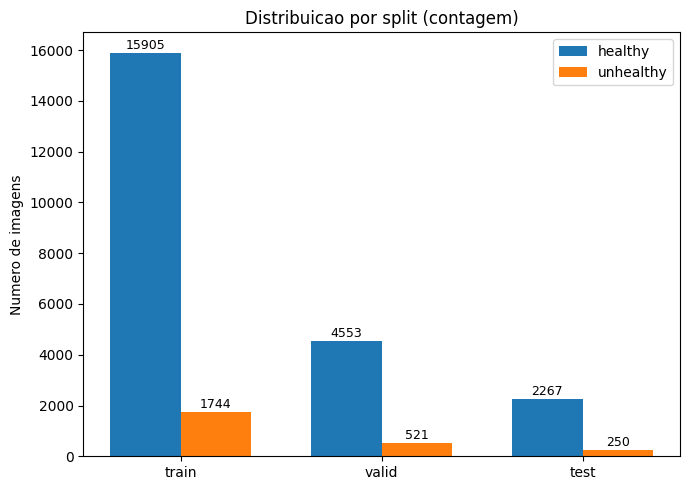

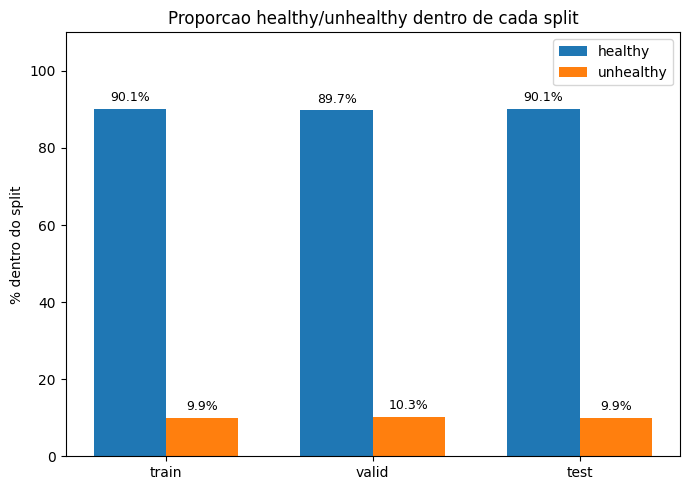

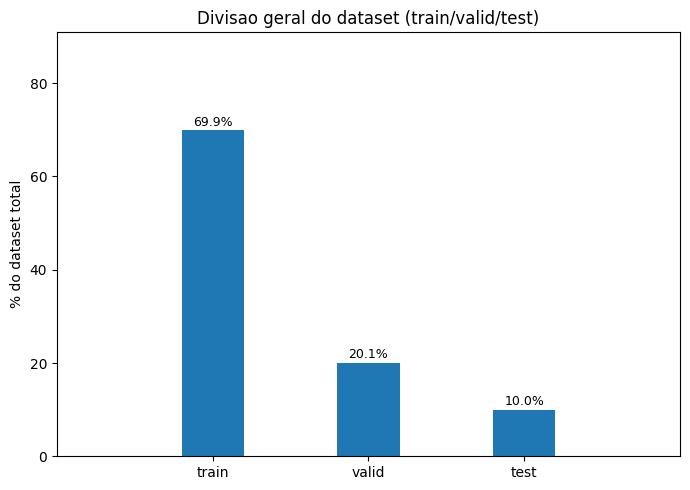

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

plt.close('all')

estratificacao = {
    "healthy":   {"train": 15905, "valid": 4553, "test": 2267},
    "unhealthy": {"train": 1744,  "valid": 521,  "test": 250},
}
splits = ["train", "valid", "test"]
x = np.arange(len(splits))
largura = 0.35

healthy_vals = [estratificacao["healthy"][s] for s in splits]
unhealthy_vals = [estratificacao["unhealthy"][s] for s in splits]
totais = [h + u for h, u in zip(healthy_vals, unhealthy_vals)]

# grafico 1: contagem absoluta
plt.figure(figsize=(7, 5))
plt.bar(x - largura/2, healthy_vals, largura, label="healthy")
plt.bar(x + largura/2, unhealthy_vals, largura, label="unhealthy")
plt.xticks(x, splits)
plt.ylabel("Numero de imagens")
plt.title("Distribuicao por split (contagem)")
plt.legend()
for i, (h, u) in enumerate(zip(healthy_vals, unhealthy_vals)):
    plt.text(i - largura/2, h + 150, str(h), ha="center", fontsize=9)
    plt.text(i + largura/2, u + 150, str(u), ha="center", fontsize=9)
plt.tight_layout()
plt.savefig(f"{RUN_DIR}/estratificacao_contagem.png", dpi=150)
plt.show()

# grafico 2: proporcao de cada classe DENTRO de cada split (healthy e unhealthy juntos)
pct_healthy = [h / t * 100 for h, t in zip(healthy_vals, totais)]
pct_unhealthy = [u / t * 100 for u, t in zip(unhealthy_vals, totais)]

plt.figure(figsize=(7, 5))
plt.bar(x - largura/2, pct_healthy, largura, label="healthy")
plt.bar(x + largura/2, pct_unhealthy, largura, label="unhealthy")
plt.xticks(x, splits)
plt.ylim(0, 110)
plt.ylabel("% dentro do split")
plt.title("Proporcao healthy/unhealthy dentro de cada split")
plt.legend()
for i, (h, u) in enumerate(zip(pct_healthy, pct_unhealthy)):
    plt.text(i - largura/2, h + 2, f"{h:.1f}%", ha="center", fontsize=9)
    plt.text(i + largura/2, u + 2, f"{u:.1f}%", ha="center", fontsize=9)
plt.tight_layout()
plt.savefig(f"{RUN_DIR}/estratificacao_proporcao_classes.png", dpi=150)
plt.show()

# grafico 3: como o dataset total foi dividido (70/20/10), sem separar por classe
total_geral = sum(totais)
pct_split = [t / total_geral * 100 for t in totais]

plt.figure(figsize=(7, 5))
plt.bar(x, pct_split, width=0.4, color="#1f77b4")
plt.xticks(x, splits)
plt.xlim(-1, len(splits))
plt.ylim(0, max(pct_split) * 1.3)
plt.ylabel("% do dataset total")
plt.title("Divisao geral do dataset (train/valid/test)")
for i, p in enumerate(pct_split):
    plt.text(i, p + 1, f"{p:.1f}%", ha="center", fontsize=9)
plt.tight_layout()
plt.savefig(f"{RUN_DIR}/split_geral.png", dpi=150)
plt.show()

## 2. Grafico de Loss (treino vs validacao)

O `results.png` que o Ultralytics gera sozinho vem como um painel com varios subgraficos pequenos. Essa celula le o `results.csv` e desenha train vs validation loss num grafico so', formato de relatorio/banca.

Colunas disponiveis no results.csv: ['epoch', 'time', 'train/loss', 'metrics/accuracy_top1', 'metrics/accuracy_top5', 'val/loss', 'lr/pg0', 'lr/pg1', 'lr/pg2', 'lr/pg3', 'lr/pg4', 'lr/pg5', 'lr/pg6', 'lr/pg7']
Salvo em: runs/classify/milho_healthy_unhealthy/loss_treino_validacao.png


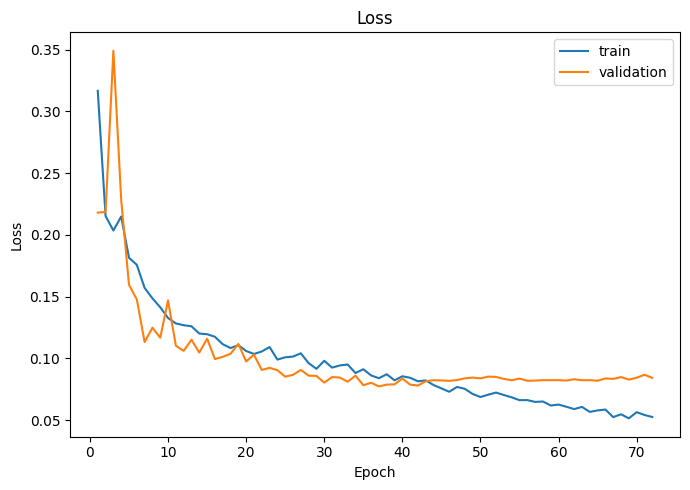

In [ ]:
import pandas as pd

df = pd.read_csv(f"{RUN_DIR}/results.csv")
df.columns = [c.strip() for c in df.columns]
print("Colunas disponiveis no results.csv:", list(df.columns))

plt.figure(figsize=(7, 5))
plt.plot(df["epoch"], df["train/loss"], label="train")
plt.plot(df["epoch"], df["val/loss"], label="validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()

saida = f"{RUN_DIR}/loss_treino_validacao.png"
plt.savefig(saida, dpi=150)
print(f"Salvo em: {saida}")
plt.show()

## 3. Curva de Accuracy (validacao)

Importante: o Ultralytics so' calcula accuracy no split de validacao a cada epoca, nao existe "accuracy de treino" por epoca pra comparar aqui (so' loss de treino, que ja foi no grafico anterior). Top-1 e Top-5 aparecem juntos.

Salvo em: runs/classify/milho_healthy_unhealthy/accuracy_validacao.png


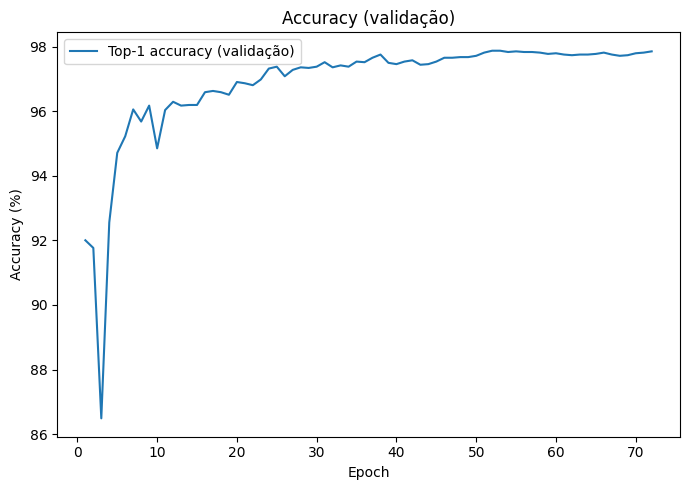

In [ ]:
plt.figure(figsize=(7, 5))
plt.plot(df["epoch"], df["metrics/accuracy_top1"] * 100, label="Top-1 accuracy (validação)")
plt.title("Accuracy (validação)")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.tight_layout()
saida = f"{RUN_DIR}/accuracy_validacao.png"
plt.savefig(saida, dpi=150)
print(f"Salvo em: {saida}")
plt.show()

## 4. Avaliacao completa no split de teste

Roda o modelo em cada imagem do `test/` e guarda, pra cada uma: classe real, classe prevista, confianca E a probabilidade bruta de cada classe (precisamos disso pras curvas ROC e Precision-Recall mais abaixo, nao so' do top1).

In [ ]:
import csv as csv_module
from pathlib import Path
from sklearn.metrics import classification_report, confusion_matrix

TEST_DIR = Path(DATASET_DIR) / "test"
classes = sorted([d.name for d in TEST_DIR.iterdir() if d.is_dir()])
print("Classes encontradas:", classes)

idx_unhealthy = [i for i, nome in model.names.items() if nome == "unhealthy"][0]

y_true, y_pred, confs, prob_unhealthy_list, paths = [], [], [], [], []

for classe in classes:
    pasta = TEST_DIR / classe
    imagens = [p for p in pasta.iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png"}]
    resultados = model.predict(imagens, verbose=False, batch=64)
    for img_path, r in zip(imagens, resultados):
        y_true.append(classe)
        y_pred.append(r.names[r.probs.top1])
        confs.append(float(r.probs.top1conf))
        prob_unhealthy_list.append(float(r.probs.data[idx_unhealthy]))
        paths.append(str(img_path))

print(f"\nTotal de imagens de teste avaliadas: {len(y_true)}\n")
print(classification_report(y_true, y_pred, digits=4))

cm = confusion_matrix(y_true, y_pred, labels=classes)
print("Matriz de confusao (linhas = real, colunas = previsto):")
print(classes)
print(cm)

with open(f"{RUN_DIR}/test_predictions.csv", "w", newline="", encoding="utf-8") as f:
    w = csv_module.writer(f)
    w.writerow(["arquivo", "classe_real", "classe_prevista", "confianca", "prob_unhealthy"])
    for path, yt, yp, c, pu in zip(paths, y_true, y_pred, confs, prob_unhealthy_list):
        w.writerow([path, yt, yp, f"{c:.4f}", f"{pu:.4f}"])
print(f"\nSalvo em: {RUN_DIR}/test_predictions.csv")

NameError: name 'DATASET_DIR' is not defined

## 5. Matriz de confusao estilizada

Salvo em: runs/classify/milho_healthy_unhealthy/confusion_matrix_custom.png


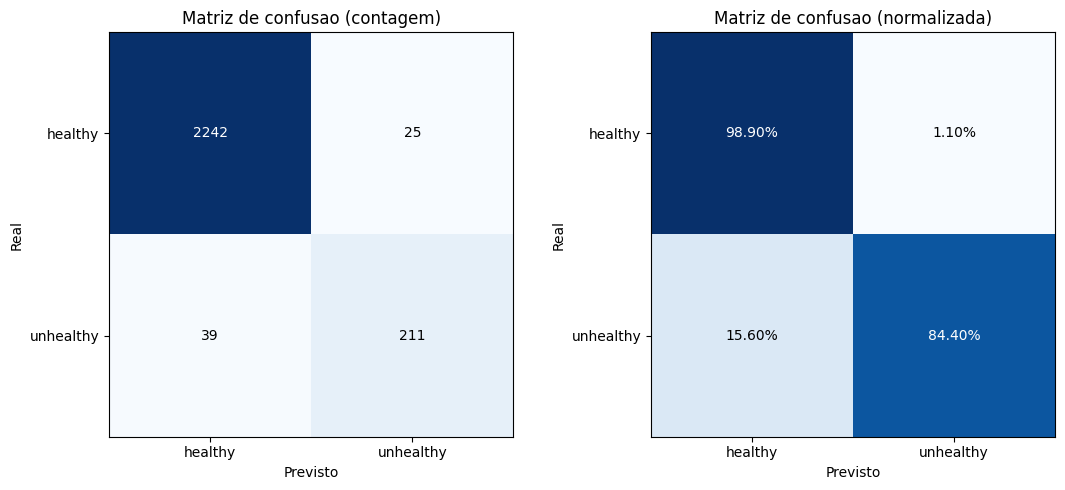

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))

for ax, normalizar, titulo in zip(axes, [False, True], ["Matriz de confusao (contagem)", "Matriz de confusao (normalizada)"]):
    dados = cm.astype(float) / cm.sum(axis=1, keepdims=True) if normalizar else cm
    im = ax.imshow(dados, cmap="Blues")
    ax.set_xticks(range(len(classes)))
    ax.set_yticks(range(len(classes)))
    ax.set_xticklabels(classes)
    ax.set_yticklabels(classes)
    ax.set_xlabel("Previsto")
    ax.set_ylabel("Real")
    ax.set_title(titulo)
    for i in range(len(classes)):
        for j in range(len(classes)):
            valor = f"{dados[i, j]:.2%}" if normalizar else str(int(dados[i, j]))
            cor_texto = "white" if dados[i, j] > dados.max() / 2 else "black"
            ax.text(j, i, valor, ha="center", va="center", color=cor_texto)

plt.tight_layout()
saida = f"{RUN_DIR}/confusion_matrix_custom.png"
plt.savefig(saida, dpi=150)
print(f"Salvo em: {saida}")
plt.show()

## 6. Curva ROC (classe unhealthy = positiva)

AUC: 0.9756
Salvo em: runs/classify/milho_healthy_unhealthy/roc_curve.png


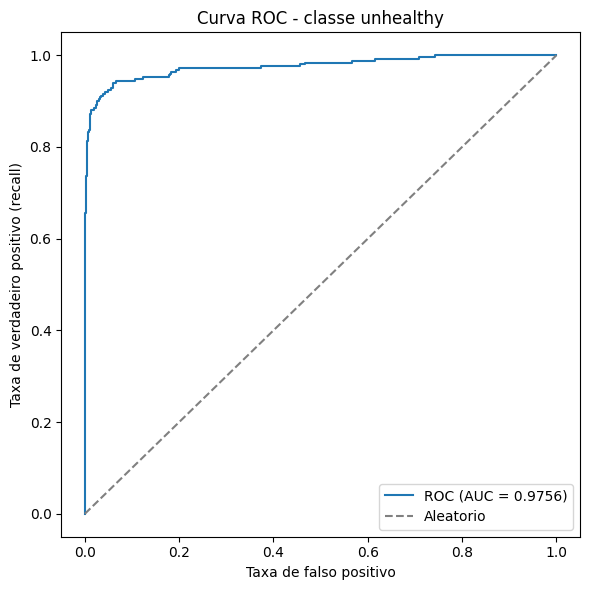

In [ ]:
from sklearn.metrics import roc_curve, auc

y_true_bin = [1 if c == "unhealthy" else 0 for c in y_true]
fpr, tpr, _ = roc_curve(y_true_bin, prob_unhealthy_list)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, label=f"ROC (AUC = {roc_auc:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Aleatorio")
plt.xlabel("Taxa de falso positivo")
plt.ylabel("Taxa de verdadeiro positivo (recall)")
plt.title("Curva ROC - classe unhealthy")
plt.legend()
plt.tight_layout()

saida = f"{RUN_DIR}/roc_curve.png"
plt.savefig(saida, dpi=150)
print(f"AUC: {roc_auc:.4f}")
print(f"Salvo em: {saida}")
plt.show()

## 7. Curva Precision-Recall (classe unhealthy)

Com 9:1 de desbalanceamento, essa curva costuma dizer mais que a ROC sobre o desempenho na classe rara.

Average Precision: 0.9252
Salvo em: runs/classify/milho_healthy_unhealthy/precision_recall_curve.png


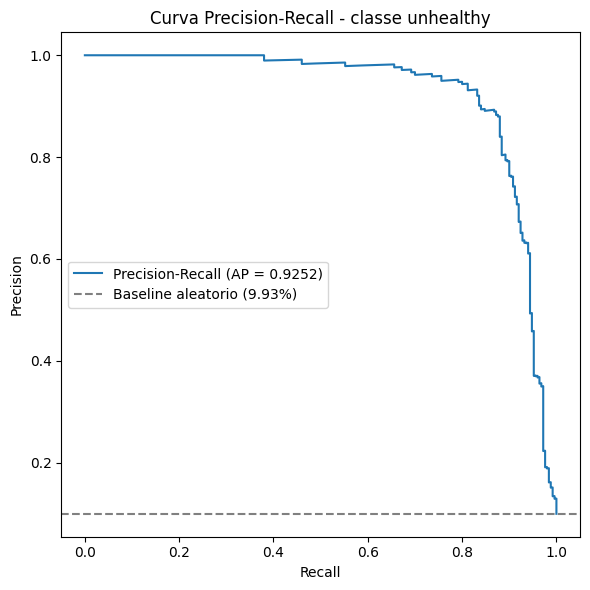

In [ ]:
from sklearn.metrics import precision_recall_curve, average_precision_score

precisions, recalls, _ = precision_recall_curve(y_true_bin, prob_unhealthy_list)
ap = average_precision_score(y_true_bin, prob_unhealthy_list)

baseline = sum(y_true_bin) / len(y_true_bin)

plt.figure(figsize=(6, 6))
plt.plot(recalls, precisions, label=f"Precision-Recall (AP = {ap:.4f})")
plt.axhline(baseline, linestyle="--", color="gray", label=f"Baseline aleatorio ({baseline:.2%})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Curva Precision-Recall - classe unhealthy")
plt.legend()
plt.tight_layout()

saida = f"{RUN_DIR}/precision_recall_curve.png"
plt.savefig(saida, dpi=150)
print(f"Average Precision: {ap:.4f}")
print(f"Salvo em: {saida}")
plt.show()

## 8. Exemplos de predicao (acertos e erros)

Salvo em: runs/classify/milho_healthy_unhealthy/exemplos_predicao.png


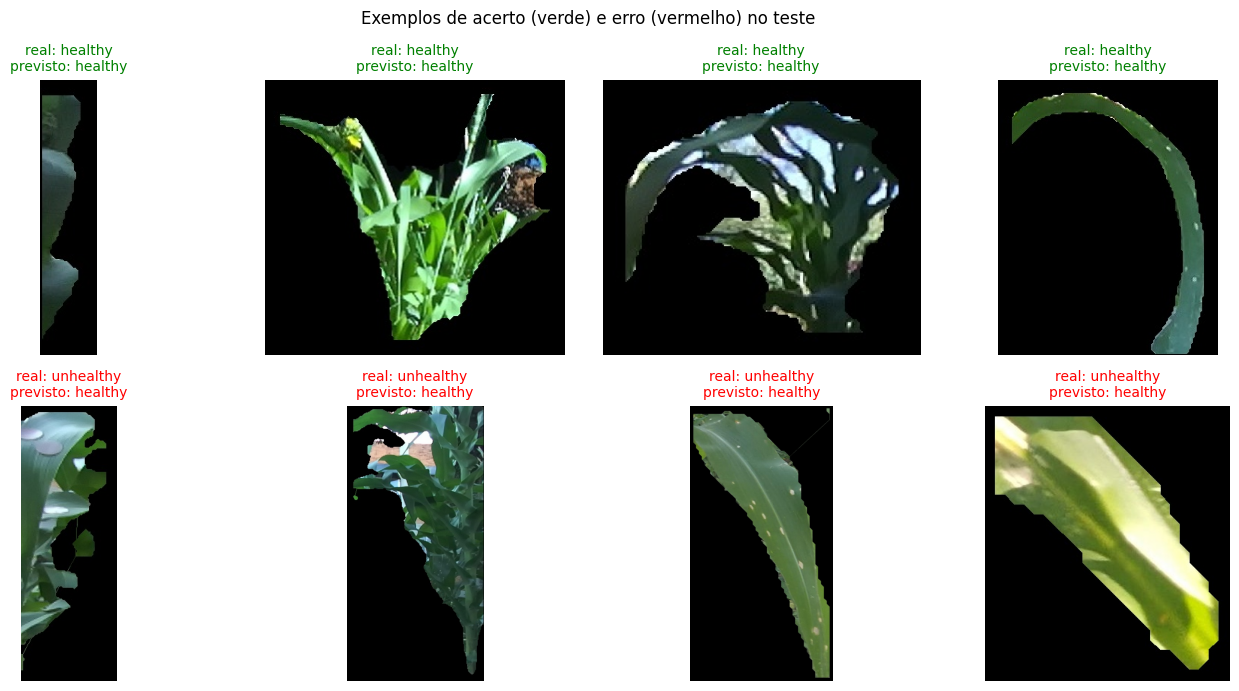

In [ ]:
import random
import cv2

acertos = [(p, yt, yp) for p, yt, yp in zip(paths, y_true, y_pred) if yt == yp]
erros = [(p, yt, yp) for p, yt, yp in zip(paths, y_true, y_pred) if yt != yp]

random.seed(0)
amostra_acertos = random.sample(acertos, min(4, len(acertos)))
amostra_erros = random.sample(erros, min(4, len(erros)))
amostra = amostra_acertos + amostra_erros

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, (path, yt, yp) in zip(axes.flat, amostra):
    img = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
    ax.imshow(img)
    cor = "green" if yt == yp else "red"
    ax.set_title(f"real: {yt}\nprevisto: {yp}", color=cor, fontsize=10)
    ax.axis("off")

plt.suptitle("Exemplos de acerto (verde) e erro (vermelho) no teste")
plt.tight_layout()
saida = f"{RUN_DIR}/exemplos_predicao.png"
plt.savefig(saida, dpi=150)
print(f"Salvo em: {saida}")
plt.show()

## Backup completo (Drive + download direto)

Zipa a pasta inteira do run (todos os pngs gerados acima, results.csv, confusion_matrix.png nativo, val_batch*_pred.jpg, test_predictions.csv, pesos) e salva em dois lugares: Drive e download direto no seu PC. Roda essa celula mesmo que algo de errado mais pra frente.

In [ ]:
import shutil, os
from google.colab import files

destino_base = "/content/drive/MyDrive/milho/relatorio_treino_completo"
os.makedirs(os.path.dirname(destino_base), exist_ok=True)

zip_path = shutil.make_archive(destino_base, 'zip', RUN_DIR)
print("Salvo no Drive:", zip_path)

print("\nConteudo do run:")
for f in sorted(os.listdir(RUN_DIR)):
    print(" ", f)

files.download(zip_path)

Salvo no Drive: /content/drive/MyDrive/milho/relatorio_treino_completo.zip

Conteudo do run:
  accuracy_validacao.png
  args.yaml
  confusion_matrix.png
  confusion_matrix_custom.png
  confusion_matrix_normalized.png
  estratificacao.png
  estratificacao_contagem.png
  estratificacao_proporcao.png
  estratificacao_proporcao_classes.png
  exemplos_predicao.png
  loss_treino_validacao.png
  precision_recall_curve.png
  results.csv
  results.png
  roc_curve.png
  split_geral.png
  test_predictions.csv
  train_batch0.jpg
  train_batch1.jpg
  train_batch2.jpg
  val_batch0_labels.jpg
  val_batch0_pred.jpg
  val_batch1_labels.jpg
  val_batch1_pred.jpg
  val_batch2_labels.jpg
  val_batch2_pred.jpg
  weights


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>